In [2]:
from MuellerLib import *
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
# from pySCATMECH.mueller import JonesMueller
import random
# from py_pol.stokes import Stokes


def pinv_rank4(B):
    """Pseudoinverse von B0 = A W, abgeschnitten auf Rang 4 (Rauschunterdrückung)."""
    U, s, Vt = np.linalg.svd(B, full_matrices=False)
    return Vt[:4].T @ np.diag(1/s[:4]) @ U[:, :4].T # Siehe markdown Eintrag

def ecm_calibrate(B, M):
	"""
	B : (K, n, m)  gemessene Matrizen B_k = A M_k W   (k=0 muss 'leer' sein)
	M : (K, 4, 4)  bekannte Mueller-Matrizen der Proben (M[0] = Identität)
	Rückgabe: A (n,4), W (4,m), eps_ECM, Singulärwerte
	"""
	K, n, m = B.shape
	B0PInv = pinv_rank4(B[0])                      # ~ W^+ A^+ -> inverse von (A W)
	# C_k = B0PInv @ B_k  = W^+ A^+ A M_k W = W^+ M_k W
	# -> W C_k = M_k W  <->  M_k W - W C_k = 0 
	# Das Kroneker-Produkt ⊗ wird verwendet, um die Gleichung in eine lineare Form zu bringen, die für alle k gleichzeitig gelöst werden kann
	# Siehe dazu das Markdown Bild unten
	# pro k Vektorisierung: vec(M W - W C) = vec(M W I_m- I_4 W C)
	# = (M ⊗ I_m - I_4 ⊗ CB0^T) vec(W) -> W hat die shape (4,m) -> vec(W) hat die Länge 4*m
	# H W = 0
	H = []
	for k in range(K):
		Ck = B0PInv @ B[k]
		H.append(np.kron(M[k], np.eye(m)) - np.kron(np.eye(4), Ck.T))
	H = np.vstack(H)
	# Gesucht ist H_k vec(X) = 0, mit rauschen ist dies jedoch nun ein minimierungsproblem
	# least squares kann auch über SVD gelöst werden, da die Lösung der kleinste Singulärwert ist
	# Kleinster Singulärwert <-> Eigenvektor von K = H^T H zum kleinsten Eigenwert
	# Die SVD von H = U S V^T -> K = V S U^T U S V^T = V S^2 V^T | V, U orthogonal, S diagonal
	# kleinster eintrag von S^2 ist der kleinste Eigenwert von K, der zugehörige Eigenvektor ist die letzte Spalte von V / Zeile von V^T
	# also reicht es nur die SVD von H zu berechnen und den letzten Eintrag von V^T zu nehmen
	U, s, Vt = np.linalg.svd(H, full_matrices=False)
	# kleinster singulärwert ist der letze diagonaleintrag von s, der zugehörige Eigenvektor ist die letzte Zeile von Vt
	W = Vt[-1].reshape(4, m)

	# Die Skalierung ist hier egal, da aus W -> aW folgt, A -> A/a => B = A/a M aW = A M W
	W = W / W[0].mean()

	# J(A) (- Abweichung vom Messwert) minimieren über alle Proben: B_k ≈ A (M_k W)
	# J(A)  = sum_k || B_k - A (M_k W) ||_F^2 Soll minimiert werden
	#       = sum_k ((B_k - A (M_k W))^T (B_k - A (M_k W)))   
	#   ... = const. + tr(sum_k A (M_k W) (M_k W)^T A^T) - 2 tr(A sum_k B_k (M_k W)^T)   
	#   ... = const. + tr(      A          C1      A^T) - 2 tr(A        C2         )  
	# Ableitung nach A: A C1 A^T    
	# 2 A C1 - 2 C2^T != 0
	# A C1 = C2^T <=> A = C2^T C1^-1 
	C1 = sum((M[k] @ W) @ (M[k] @ W).T for k in range(K))
	C2 = sum(B[k] @ (M[k] @ W).T for k in range(K))
	A = C2 @ np.linalg.inv(C1)

	eps_ecm = s[-1] / s[-2]                     # verhältnis der kleinsten Singulärwerte, sollte sehr klein sein, s[-1] -> 0
	return A, W, eps_ecm, s

def reconstMueller(A:np.ndarray, Res:np.ndarray, W:np.ndarray):
	"""
	Args:
		A : Generator 
		Res : Ergebisse
		W : Analysator

	Returns:
		np.ndarray: Rekonstruierte Muellermatritzen
	"""
	Designmatrix = np.kron(A, W.T)   
	Inverse = np.linalg.pinv(Designmatrix)
	reconst = Res @ Inverse.T
	return reconst.reshape(-1, 4, 4)

def LuChipman(M, eps=1e-12):
    """
    M: (N,4,4) Mueller-Matrizen
    Rückgabe (alle Winkel in rad, shape (N,)):
      diattenuation, depolarization, linear_ret, circular_ret, orientation
    Zerlegung: M = M_Delta @ M_R @ M_D
    """
    M = np.asarray(M, dtype=float)
    M = M / M[:, :1, :1]                      # Normierung auf M00 = 1

    # ---- 1) Diattenuator M_D -------------------------------------------
    Dvec = M[:, 0, 1:]                        # (N,3)
    D = np.linalg.norm(Dvec, axis=1)          # Diattenuation
    D = np.minimum(D, 1 - eps)                # D=1 wäre singulär
    Dhat = Dvec / np.maximum(np.linalg.norm(Dvec, axis=1), eps)[:, None]
    Dvec = Dhat * D[:, None]

    sq = np.sqrt(1 - D**2)
    I3 = np.eye(3)
    mD = sq[:, None, None] * I3 + (1 - sq)[:, None, None] * (Dhat[:, :, None] * Dhat[:, None, :])

    MD = np.zeros_like(M)
    MD[:, 0, 0] = 1
    MD[:, 0, 1:] = Dvec
    MD[:, 1:, 0] = Dvec
    MD[:, 1:, 1:] = mD

    # ---- 2) M' = M_Delta @ M_R = M @ M_D^-1 ----------------------------
    Mp = M @ np.linalg.inv(MD)
    mp = Mp[:, 1:, 1:]                        # (N,3,3)

    # ---- 3) Depolarisator m_Delta über Eigenwerte von m' m'^T ----------
    A = mp @ mp.transpose(0, 2, 1)
    lam = np.clip(np.linalg.eigvalsh(A), 0, None)   # (N,3)
    s = np.sqrt(lam)
    s1 = s.sum(1)
    s2 = s[:, 0]*s[:, 1] + s[:, 1]*s[:, 2] + s[:, 2]*s[:, 0]
    s3 = s.prod(1)                            # = |det m'|
    sign = np.where(np.linalg.det(mp) < 0, -1.0, 1.0)

    lhs = A + s2[:, None, None] * I3
    rhs = s1[:, None, None] * A + s3[:, None, None] * I3
    mDelta = sign[:, None, None] * np.linalg.solve(lhs, rhs)

    depol = 1 - np.abs(np.trace(mDelta, axis1=1, axis2=2)) / 3

    # ---- 4) Retarder m_R = m_Delta^-1 @ m' -----------------------------
    mR = np.linalg.solve(mDelta, mp)

    tr = np.trace(mR, axis1=1, axis2=2)
    R = np.arccos(np.clip((tr - 1) / 2, -1, 1))     # Gesamtretardance
    sinR = np.sin(R)
    f = np.where(sinR > 1e-9, R / (2 * np.where(sinR > 1e-9, sinR, 1)), 0.5)

    a1 = f * (mR[:, 1, 2] - mR[:, 2, 1])      # Q-Komponente
    a2 = f * (mR[:, 2, 0] - mR[:, 0, 2])      # U-Komponente
    a3 = f * (mR[:, 0, 1] - mR[:, 1, 0])      # V-Komponente

    lin_ret = np.hypot(a1, a2)
    circ_ret = a3
    orientation = 0.5 * np.arctan2(a2, a1)    # schnelle Achse, in (-π/2, π/2]

    return D, depol, lin_ret, circ_ret, orientation

In [4]:
# --------------------------------------- Bilder als Retardierung und Orientierung eines Linearen Retarder verwenden
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
import skimage as ski
from skimage.color import rgb2gray
from skimage.transform import resize
CamImg = Image.open("TheCameraman.png")
USAFImg = np.array(resize(rgb2gray(ski.data.astronaut()), (256,256)).reshape(256,256))#Image.open("USAFcut.png") # USAFcut.png lena_gray_256

Thetas = np.array(CamImg).ravel()/255*180
deltas = np.array(USAFImg).ravel()*180 #/255

Probe = np.array([MuellerRetarder(delt, thet) for thet, delt in zip(Thetas, deltas)])


# ------------------------------------------------------------------------------- Die Messung mit dem Polarimeter Simulieren
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------

# S' = GMA S /  G- generator, M- Müllermatritze der Probe, A- Analysator
#    = LinPol @ Ret @ Probe @ Ret @ LinPol @ SQuelle
# Analyser = MuellerLinearPolarizer(0) @ MuellerRetarder(90, 0) 
# Generator = MuellerRetarder(90, 0) @ MuellerLinearPolarizer(0)
ReconstError = []
RetardierungError = []
OrientationError = []
delt = np.arange(10, 180, 1) # 132 Literaturwert, ist wohl stabiler :D ..... Austesten  NACHLESEN
for delta in delt:
	AnzWinkel = 36
	# Aus der Optimierung
	thetas =  np.array([ 99.93809444,  53.16435397, 126.5536744,  149.56851851,  30.25052659,  79.95532736])# np.arange(0, 180, int(180/np.sqrt(AnzWinkel)))

	RetMat = np.array([MuellerRetarder(delta, theta) for theta in thetas])
	LinPolMat = MuellerLinearPolarizer(0)
	I0 = 1
	SQuelle = np.array([I0,0,0,0])
	N = len(RetMat)  # Anzahl Einstellungen pro retarder
	# GeneratorS = np.einsum('nij,jk,k->ni', RetMat, LinPolMat, SQuelle)   # shape (N, 4)
	Proben = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
	GeneratorS = RetMat @ LinPolMat @ SQuelle # (6, 4, 4) @ (4,4) @ (4,1) = (6,4,4)@(4,1) = (6,4,1)=(6,4) -> gewünscht ist (4,6), ein stokes vektor für jede einstellung des Retarders
	Analysator = LinPolMat @ RetMat           # shape (N, 4, 4)
	# Analysator[:,0,:] nur erste Zeile relevant, da nur die Intensität gemessen wird
	# (6,4)@(4,4,4)@(6,4).T = (6,4)@(4,4,4)@(4,6) = (6,4)@(4,4,6) = (4,6,6) -> reshape -> (4,36) Intensitäten der 36 Kombinationen der Einstellungen der retarder pro Probe
	SRes = (Analysator[:,0,:] @ Proben @ GeneratorS.T).reshape(4, N * N)
	# ------------------------------------------------------------------------------ Die Kalibration, Aufstellung von W und A
	# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
	n, m = 6, 6                                    # n*m = 36, anzahl der einstellungen for Analysator und Generator
	# SRes, shape (4, 36), 4 verschiedene Proben mit je 36 Messungen
	cmw = SRes.reshape(4, n, m)                    # Zeile n = Analysator, Spalte m = Generator
	A, W, eps, s = ecm_calibrate(cmw, Proben)
	# ----------------------------------------------------------------- Rekonstruktion der Probematritze, basierent auf den Kalibrierten Matrizen
	# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
	noise = np.random.normal(0, 0.01, size=(256*256, 36))
	# SRes = (A @ Probe @ W) + noise  # Simulierte Messung mit Rauschen
	SRes = (A @ Probe @ W).reshape(-1, N*N) + noise
	# Sres = np.einsum('zj,pjk,tk->ptz', A, Probe, W).reshape(Probe.shape[0], N * N) 
	Reconst = reconstMueller(A, SRes, W)
	MMD_D, MMD_Delta, MMD_LR, MMD_CR, MMD_psi = LuChipman(Reconst.reshape(256*256,4,4))


	ReconstError.append(np.sum(np.abs(Reconst - Probe))/(Reconst.shape[0]*Reconst.shape[1]*Reconst.shape[2]))
	RetardierungError.append(np.sum(np.abs(np.cos(MMD_LR) - np.cos(np.deg2rad(deltas))))/deltas.shape[0])# (np.sum(np.abs(MMD_LR - deltas))/deltas.shape[0])
	OrientationError.append(np.sum(np.abs(np.cos(MMD_psi+np.pi/2) - np.cos(np.deg2rad(Thetas))))/thetas.shape[0])# (np.sum(np.abs(MMD_psi - Thetas))/thetas.shape[0])

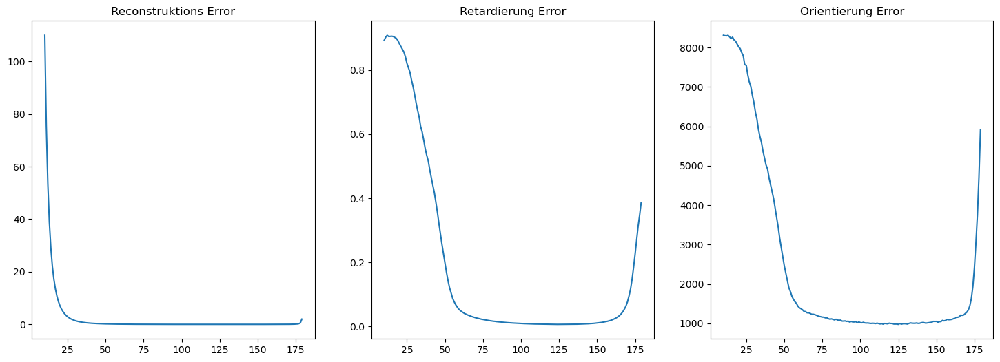

In [7]:
plt.figure(figsize=(18, 6))
plt.subplot(1,3,1)
plt.title("Reconstruktions Error")
plt.plot(delt, ReconstError)
plt.subplot(1,3,2)
plt.title("Retardierung Error")
plt.plot(delt, RetardierungError)
plt.subplot(1,3,3)
plt.title("Orientierung Error")
plt.plot(delt, OrientationError)

In [8]:
# --------------------------------------- Bilder als Retardierung und Orientierung eines Linearen Retarder verwenden
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
import skimage as ski
from skimage.color import rgb2gray
from skimage.transform import resize
CamImg = Image.open("TheCameraman.png")
USAFImg = np.array(resize(rgb2gray(ski.data.astronaut()), (256,256)).reshape(256,256))#Image.open("USAFcut.png") # USAFcut.png lena_gray_256

Thetas = np.array(CamImg).ravel()/255*180
deltas = np.array(USAFImg).ravel()*180 + 0.2#/255

Probe = np.array([MuellerRetarder(delt, thet) for thet, delt in zip(Thetas, deltas)])


# ------------------------------------------------------------------------------- Die Messung mit dem Polarimeter Simulieren
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------

# S' = GMA S /  G- generator, M- Müllermatritze der Probe, A- Analysator
#    = LinPol @ Ret @ Probe @ Ret @ LinPol @ SQuelle
# Analyser = MuellerLinearPolarizer(0) @ MuellerRetarder(90, 0) 
# Generator = MuellerRetarder(90, 0) @ MuellerLinearPolarizer(0)

delta = 132 # 132 Literaturwert, ist wohl stabiler :D ..... Austesten  NACHLESEN

AnzWinkel = 36
# Aus der Optimierung
thetas =  np.array([ 99.93809444,  53.16435397, 126.5536744,  149.56851851,  30.25052659,  79.95532736])# np.arange(0, 180, int(180/np.sqrt(AnzWinkel)))

RetMat = np.array([MuellerRetarder(delta, theta) for theta in thetas])
LinPolMat = MuellerLinearPolarizer(0)
I0 = 1
SQuelle = np.array([I0,0,0,0])
N = len(RetMat)  # Anzahl Einstellungen pro retarder
# GeneratorS = np.einsum('nij,jk,k->ni', RetMat, LinPolMat, SQuelle)   # shape (N, 4)
Proben = np.array([np.eye(4), MuellerLinearPolarizer(0), MuellerLinearPolarizer(45), MuellerRetarder(90,0)])
GeneratorS = RetMat @ LinPolMat @ SQuelle # (6, 4, 4) @ (4,4) @ (4,1) = (6,4,4)@(4,1) = (6,4,1)=(6,4) -> gewünscht ist (4,6), ein stokes vektor für jede einstellung des Retarders
Analysator = LinPolMat @ RetMat           # shape (N, 4, 4)
# Analysator[:,0,:] nur erste Zeile relevant, da nur die Intensität gemessen wird
# (6,4)@(4,4,4)@(6,4).T = (6,4)@(4,4,4)@(4,6) = (6,4)@(4,4,6) = (4,6,6) -> reshape -> (4,36) Intensitäten der 36 Kombinationen der Einstellungen der retarder pro Probe
SRes = (Analysator[:,0,:] @ Proben @ GeneratorS.T).reshape(4, N * N)
# ------------------------------------------------------------------------------ Die Kalibration, Aufstellung von W und A
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
n, m = 6, 6                                    # n*m = 36, anzahl der einstellungen for Analysator und Generator
# SRes, shape (4, 36), 4 verschiedene Proben mit je 36 Messungen
cmw = SRes.reshape(4, n, m)                    # Zeile n = Analysator, Spalte m = Generator
A, W, eps, s = ecm_calibrate(cmw, Proben)
# ----------------------------------------------------------------- Rekonstruktion der Probematritze, basierent auf den Kalibrierten Matrizen
# ---------------------------------------------------------------------------------------------------------------------------------------------------------------------
noise = np.random.normal(0, 0.01, size=(256*256, 36))
# SRes = (A @ Probe @ W) + noise  # Simulierte Messung mit Rauschen
SRes = (A @ Probe @ W).reshape(-1, N*N) + noise
# Sres = np.einsum('zj,pjk,tk->ptz', A, Probe, W).reshape(Probe.shape[0], N * N) 
Reconst = reconstMueller(A, SRes, W)
MMD_D, MMD_Delta, MMD_LR, MMD_CR, MMD_psi = LuChipman(Reconst.reshape(256*256,4,4))


SingleReconstError = (np.sum(np.abs(Reconst - Probe))/(Reconst.shape[0]*Reconst.shape[1]*Reconst.shape[2]))
SingleRetardierungError = (np.sum(np.abs(np.cos(MMD_LR) - np.cos(np.deg2rad(deltas))))/deltas.shape[0])
SingleOrientationError = (np.sum(np.abs(np.cos(MMD_psi+np.pi/2) - np.cos(np.deg2rad(Thetas))))/thetas.shape[0])
SingleReconstError,SingleRetardierungError,SingleOrientationError

(np.float64(0.012771455527459175),
 np.float64(0.00707800999759888),
 np.float64(894.306295689024))

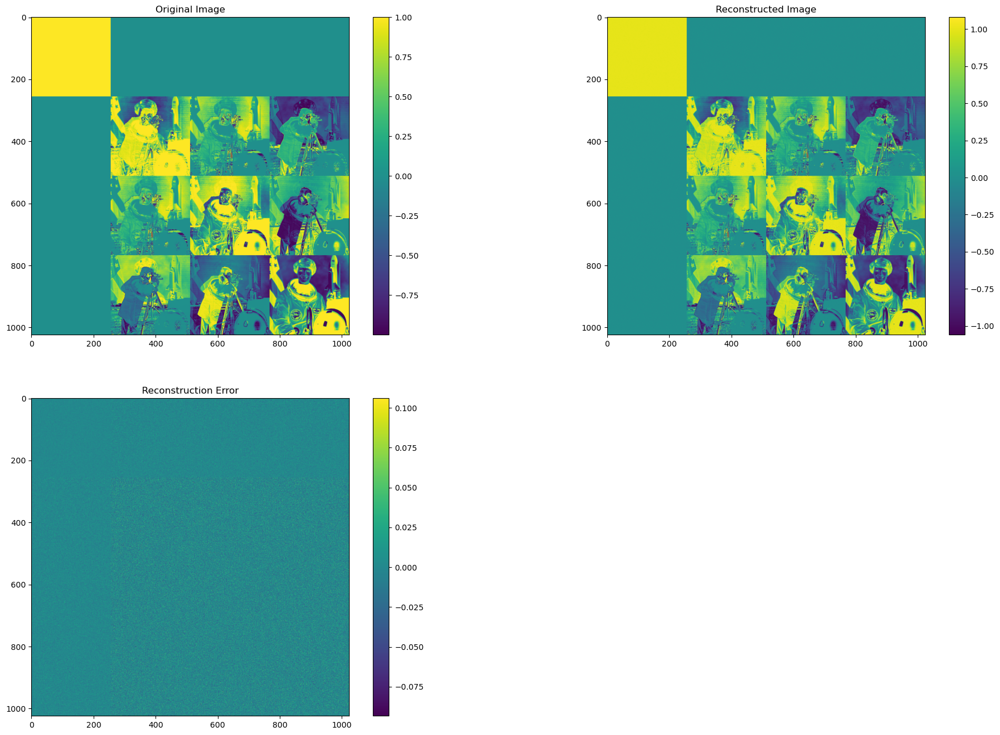

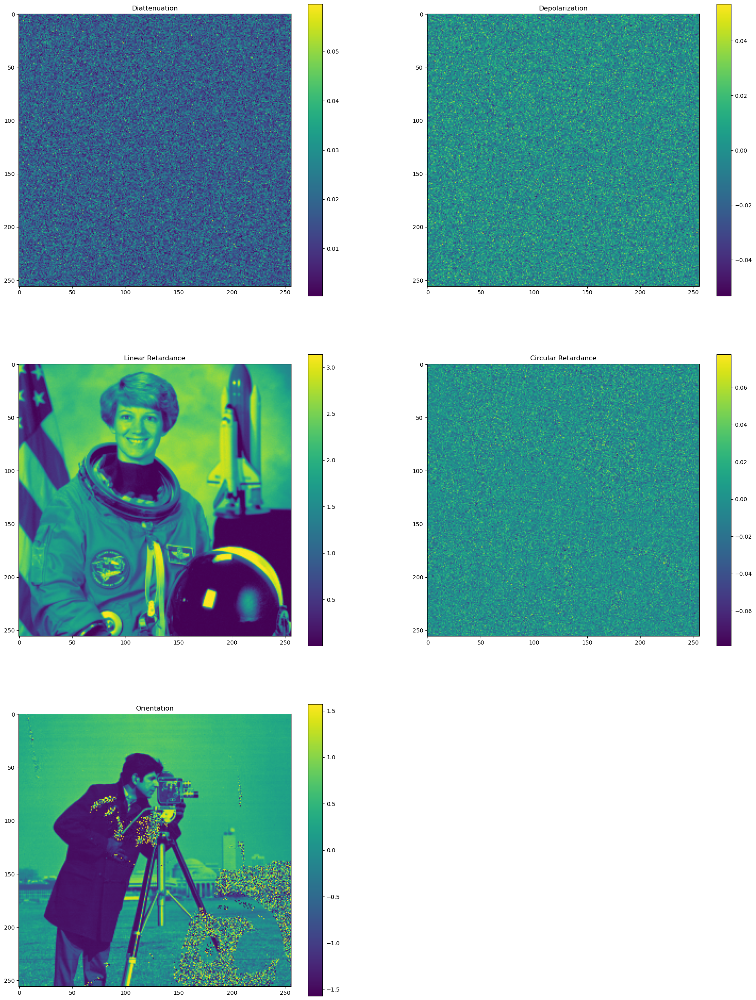

In [9]:
plt.figure(figsize=(24, 16))
plt.subplot(2, 2, 1)
plt.title("Original Image")
OrigImage = Probe.reshape(256, 256, 4, 4)
OrigImage = OrigImage.transpose(2, 0, 3, 1)
OrigImage = OrigImage.reshape(4*256, 4*256)
plt.imshow(OrigImage, cmap="viridis")
plt.colorbar()

plt.subplot(2, 2, 2)
plt.title("Reconstructed Image")
RecImage = Reconst.reshape(256, 256, 4, 4)
RecImage = RecImage.transpose(2, 0, 3, 1)
RecImage = RecImage.reshape(4*256, 4*256)
plt.imshow(RecImage, cmap="viridis")
plt.colorbar()

plt.subplot(2,2,3)
plt.title("Reconstruction Error")
Error = OrigImage-RecImage
plt.imshow(Error, cmap="viridis")
plt.colorbar()

plt.show()

plt.figure(figsize=(24, 32))
plt.subplot(3, 2, 1)
plt.title("Diattenuation")
plt.imshow(MMD_D.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3, 2, 2)
plt.title("Depolarization")
plt.imshow(MMD_Delta.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Linear Retardance")
plt.imshow(MMD_LR.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,4)
plt.title("Circular Retardance")
plt.imshow(MMD_CR.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation")
plt.imshow(MMD_psi.reshape(256,256), cmap="viridis")
plt.colorbar()

MMD parameter calculation completed!
Elapsed time: 10.651888847351074 seconds


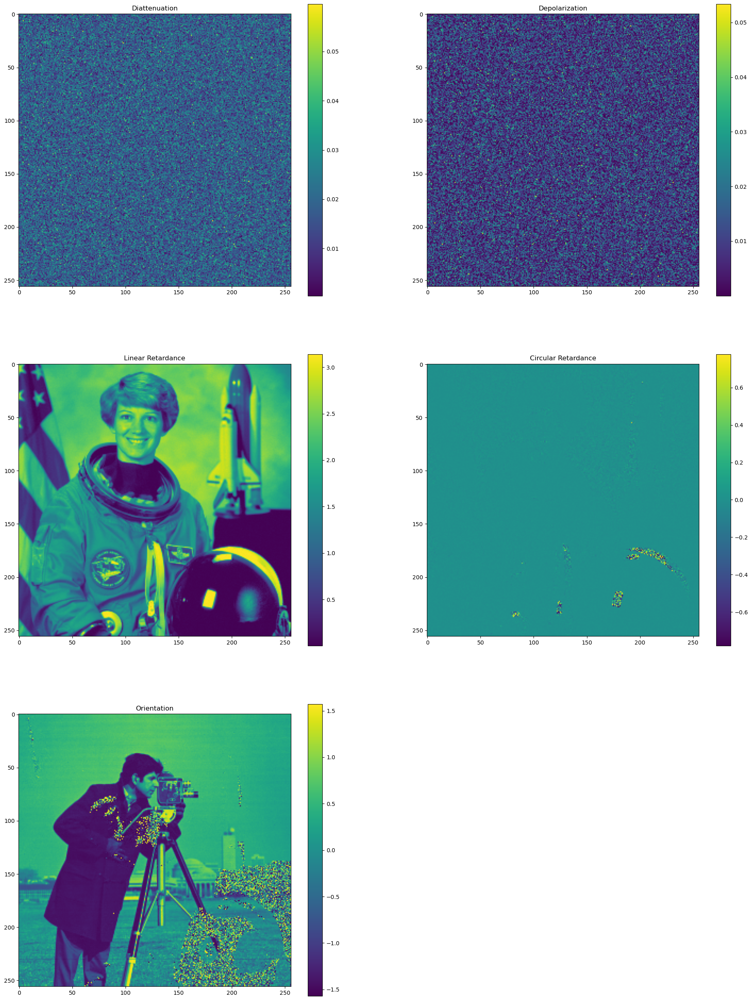

In [10]:
from pymueller.decomposition import lu_chipman

MMD_D, MMD_Delta, MMD_LR, MMD_CR, MMD_psi = lu_chipman(256, 256, Reconst.reshape(256,256,16))

plt.figure(figsize=(24, 32))
plt.subplot(3, 2, 1)
plt.title("Diattenuation")
plt.imshow(MMD_D, cmap="viridis")
plt.colorbar()

plt.subplot(3, 2, 2)
plt.title("Depolarization")
plt.imshow(MMD_Delta, cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Linear Retardance")
plt.imshow(MMD_LR, cmap="viridis")
plt.colorbar()

plt.subplot(3,2,4)
plt.title("Circular Retardance")
plt.imshow(MMD_CR, cmap="viridis")
plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation")
plt.imshow(MMD_psi, cmap="viridis")
plt.colorbar()

/tmp/ipykernel_6454/3228442576.py:11: RuntimeWarning: invalid value encountered in arccos
  delta = np.arccos(Reconst[:,3,3])


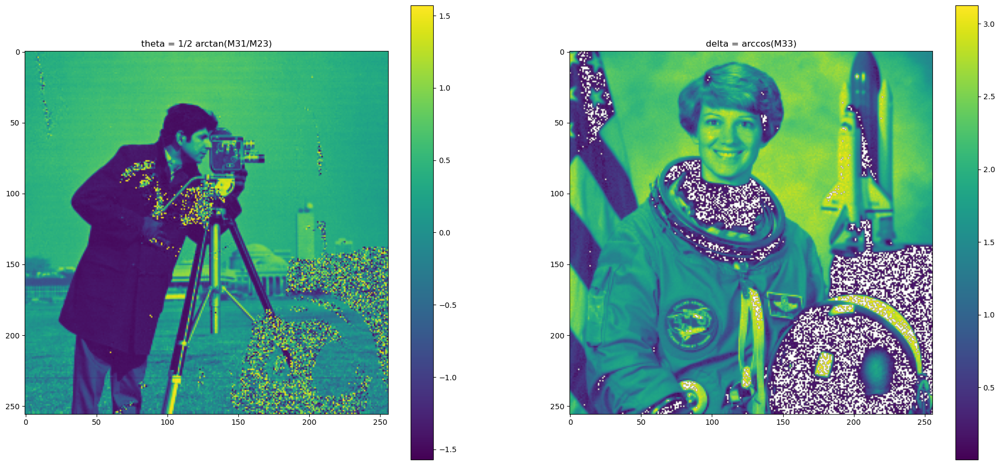

In [11]:
plt.figure(figsize=(24, 11))
plt.subplot(1,2,1)
plt.title("theta = 1/2 arctan(M31/M23)")
M31 = Reconst[:,3,1]
M23 = Reconst[:,2,3]
theta = 1/2 * np.arctan2(M31,M23)
plt.imshow(theta.reshape((256,256)))
plt.colorbar()
plt.subplot(1,2,2)
plt.title("delta = arccos(M33)")
delta = np.arccos(Reconst[:,3,3])
plt.imshow(delta.reshape((256,256)))
plt.colorbar()

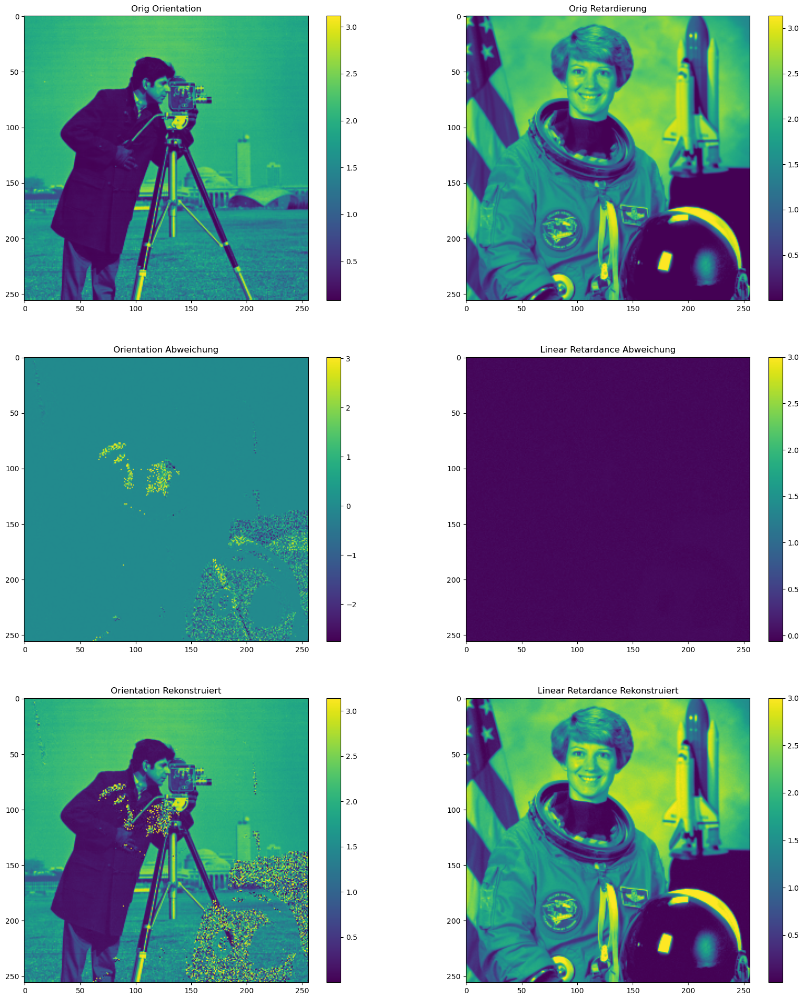

In [17]:
plt.figure(figsize=(20,24))
plt.subplot(3,2,1)
plt.title("Orig Orientation")
plt.imshow(np.deg2rad(Thetas).reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,2)
plt.title("Orig Retardierung")
plt.imshow(np.deg2rad(deltas).reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Orientation Abweichung")
plt.imshow(MMD_psi.reshape(256,256)+np.pi/2-np.deg2rad(Thetas).reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,4)
plt.title("Linear Retardance Abweichung")
plt.imshow(MMD_LR.reshape(256,256)-np.deg2rad(deltas).reshape(256,256), cmap="viridis", vmax=3)
plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation Rekonstruiert")
plt.imshow(MMD_psi.reshape(256,256)+np.pi/2, cmap="viridis")
plt.colorbar()

plt.subplot(3,2,6)
plt.title("Linear Retardance Rekonstruiert")
plt.imshow(MMD_LR.reshape(256,256), cmap="viridis", vmax=3)
plt.colorbar()

# LuChipman Fehler für kleine Retardierungswerte analysieren

In [ ]:
def LuChipman(M, eps=1e-12):
    """
    M: (N,4,4) Mueller-Matrizen
    Rückgabe (alle Winkel in rad, shape (N,)):
      diattenuation, depolarization, linear_ret, circular_ret, orientation
    Zerlegung: M = M_Delta @ M_R @ M_D
    """
    M = np.asarray(M, dtype=float)
    M = M / M[:, :1, :1]                      # Normierung auf M00 = 1

    # ---- 1) Diattenuator M_D -------------------------------------------
    Dvec = M[:, 0, 1:]                        # (N,3)
    D = np.linalg.norm(Dvec, axis=1)          # Diattenuation
    D = np.minimum(D, 1 - eps)                # D=1 wäre singulär
    Dhat = Dvec / np.maximum(np.linalg.norm(Dvec, axis=1), eps)[:, None]
    Dvec = Dhat * D[:, None]

    sq = np.sqrt(1 - D**2)
    I3 = np.eye(3)
    mD = sq[:, None, None] * I3 + (1 - sq)[:, None, None] * (Dhat[:, :, None] * Dhat[:, None, :])

    MD = np.zeros_like(M)
    MD[:, 0, 0] = 1
    MD[:, 0, 1:] = Dvec
    MD[:, 1:, 0] = Dvec
    MD[:, 1:, 1:] = mD

    # ---- 2) M' = M_Delta @ M_R = M @ M_D^-1 ----------------------------
    Mp = M @ np.linalg.inv(MD)
    mp = Mp[:, 1:, 1:]                        # (N,3,3)

    # ---- 3) Depolarisator m_Delta über Eigenwerte von m' m'^T ----------
    A = mp @ mp.transpose(0, 2, 1)
    lam = np.clip(np.linalg.eigvalsh(A), 0, None)   # (N,3)
    s = np.sqrt(lam)
    s1 = s.sum(1)
    s2 = s[:, 0]*s[:, 1] + s[:, 1]*s[:, 2] + s[:, 2]*s[:, 0]
    s3 = s.prod(1)                            # = |det m'|
    sign = np.where(np.linalg.det(mp) < 0, -1.0, 1.0)

    lhs = A + s2[:, None, None] * I3
    rhs = s1[:, None, None] * A + s3[:, None, None] * I3
    mDelta = sign[:, None, None] * np.linalg.solve(lhs, rhs)

    depol = 1 - np.abs(np.trace(mDelta, axis1=1, axis2=2)) / 3

    # ---- 4) Retarder m_R = m_Delta^-1 @ m' -----------------------------
    mR = np.linalg.solve(mDelta, mp)

    tr = np.trace(mR, axis1=1, axis2=2)
    R = np.arccos(np.clip((tr - 1) / 2, -1, 1))     # Gesamtretardance
    sinR = np.sin(R)
    f = np.where(sinR > 1e-9, R / (2 * np.where(sinR > 1e-9, sinR, 1)), 0.5)

    a1 = f * (mR[:, 1, 2] - mR[:, 2, 1])      # Q-Komponente
    a2 = f * (mR[:, 2, 0] - mR[:, 0, 2])      # U-Komponente
    a3 = f * (mR[:, 0, 1] - mR[:, 1, 0])      # V-Komponente

    lin_ret = np.hypot(a1, a2)
    circ_ret = a3
    orientation = 0.5 * np.arctan2(a2, a1)    # schnelle Achse, in (-π/2, π/2]

    return D, depol, lin_ret, circ_ret, orientation

In [ ]:
import numpy as np

def lin_ret_orientation_fast(M, eps=1e-12):
    m = M[:, 1:, 1:] / M[:, :1, :1]
    v1 = m[:, 1, 2] - m[:, 2, 1]
    v2 = m[:, 2, 0] - m[:, 0, 2]
    v3 = m[:, 0, 1] - m[:, 1, 0]
    tr = m[:, 0, 0] + m[:, 1, 1] + m[:, 2, 2]

    vn = np.sqrt(v1*v1 + v2*v2 + v3*v3)
    rho = np.hypot(tr, vn)
    R = np.arctan2(vn, tr) + np.arcsin(np.clip(vn / (2*np.maximum(rho, eps)), -1, 1))
    R = np.minimum(R, np.pi)

    lin = R * np.hypot(v1, v2) / np.maximum(vn, eps)
    theta = 0.5 * np.arctan2(v2, v1)
    return lin, theta

In [27]:
import numpy as np

def lu_chipman_svd(M, eps=1e-12):
    """
    M: (N,4,4) Mueller-Matrizen
    Rückgabe (Winkel in rad, je shape (N,)):
      diattenuation, depolarization, linear_ret, circular_ret, orientation
    Zerlegung: M = M_Delta @ M_R @ M_D
    """
    M = np.asarray(M, dtype=float)
    N = M.shape[0]
    M = M / M[:, :1, :1]
    I3 = np.eye(3)

    # ---- 1) Diattenuator -------------------------------------------------
    Dvec = M[:, 0, 1:]
    Dn = np.linalg.norm(Dvec, axis=1)
    D = np.minimum(Dn, 1 - eps)
    Dhat = Dvec / np.maximum(Dn, eps)[:, None]
    Dvec = Dhat * D[:, None]

    sq = np.sqrt(1 - D**2)
    mD = (sq[:, None, None] * I3
          + (1 - sq)[:, None, None] * (Dhat[:, :, None] * Dhat[:, None, :]))
    MD = np.zeros_like(M)
    MD[:, 0, 0] = 1
    MD[:, 0, 1:] = Dvec
    MD[:, 1:, 0] = Dvec
    MD[:, 1:, 1:] = mD

    # ---- 2) Diattenuation herausrechnen: M' = M @ M_D^-1 ------------------
    mp = (M @ np.linalg.inv(MD))[:, 1:, 1:]

    # ---- 3) SVD: m' = U diag(S) Vt  ---------------------------------------
    U, S, Vt = np.linalg.svd(mp)
    Q = U @ Vt                                   # orthogonal, det = ±1
    s = np.where(np.linalg.det(Q) < 0, -1.0, 1.0)

    depol = 1 - S.sum(axis=1) / 3                # Δ = 1 - |tr(mΔ)|/3
    mR = s[:, None, None] * Q                    # Rotation, det = +1

    # ---- 4) Retardance-Vektor aus mR --------------------------------------
    v = np.stack([mR[:, 1, 2] - mR[:, 2, 1],
                  mR[:, 2, 0] - mR[:, 0, 2],
                  mR[:, 0, 1] - mR[:, 1, 0]], axis=1)          # = 2 sin(R) * n
    vn = np.linalg.norm(v, axis=1)
    cosR = (np.trace(mR, axis1=1, axis2=2) - 1) / 2
    R = np.arctan2(vn / 2, cosR)                 # stabiler als arccos

    # Achse: normal aus v, nahe R = π aus dem symmetrischen Anteil
    n = v / np.maximum(vn, eps)[:, None]

    near_pi = (vn < 1e-3) & (cosR < 0)
    if near_pi.any():
        idx = np.nonzero(near_pi)[0]
        Ssym = 0.5 * (mR[idx] + mR[idx].transpose(0, 2, 1))
        B = (Ssym - cosR[idx, None, None] * I3) / (1 - cosR[idx])[:, None, None]
        k = np.argmax(np.einsum('nii->ni', B), axis=1)
        col = B[np.arange(len(idx)), :, k]
        col /= np.maximum(np.linalg.norm(col, axis=1), eps)[:, None]
        sg = np.sign(np.einsum('ni,ni->n', col, v[idx]))
        sg[sg == 0] = 1.0
        n[idx] = col * sg[:, None]

    a = R[:, None] * n                           # Retardance-Vektor
    lin_ret = np.hypot(a[:, 0], a[:, 1])
    circ_ret = a[:, 2]
    orientation = 0.5 * np.arctan2(a[:, 1], a[:, 0])

    return D, depol, lin_ret, circ_ret, orientation

In [19]:
M = Reconst
eps=1e-12
vn_small=1e-3
ret_min=1e-3
"""
M: (N,4,4) Mueller-Matrizen
Rückgabe (Winkel in rad, je shape (N,)):
	diattenuation, depolarization, linear_ret, circular_ret, orientation
Zerlegung: M = M_Delta @ M_R @ M_D
orientation = NaN, wo lin_ret < ret_min (Orientation dort undefiniert)
"""
M = np.asarray(M, dtype=float)
M = M / M[:, :1, :1]
I3 = np.eye(3)

# ---- 1) Diattenuator -------------------------------------------------
Dvec = M[:, 0, 1:] # M01, M02, M03
Dn = np.linalg.norm(Dvec, axis=1) # Norm der 3er vektoren
D = np.minimum(Dn, 1 - eps) # Dn mit maximal 1 - eps, ist diretk die diattenuation
Dhat = Dvec / np.maximum(Dn, eps)[:, None] # Normieren mit max 1-eps und min eps
Dvec = Dhat * D[:, None] # Rescarlieren, garantiert die boundaries von (eps, 1-eps)

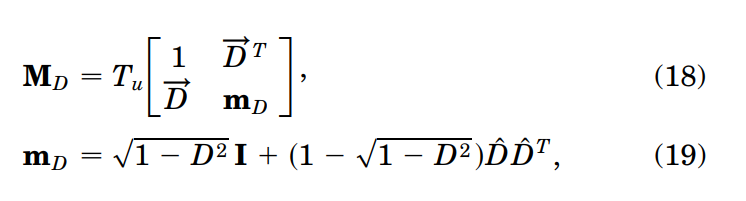

In [20]:
# siehe JOSAA.13.001106.pdf für die genaue Formulierung
sq = np.sqrt(1 - D**2) # Diagonaleinträge (Anteil)
mD = (sq[:, None, None] * I3
		+ (1 - sq)[:, None, None] * (Dhat[:, :, None] * Dhat[:, None, :]))   # JOSAA.13.001106.pdf Gl. (19)
MD = np.zeros_like(M)
MD[:, 0, 0] = 1
MD[:, 0, 1:] = Dvec
MD[:, 1:, 0] = Dvec
MD[:, 1:, 1:] = mD

# ---- 2) Diattenuation herausrechnen: M' = M @ M_D^-1 ------------------
mp = (M @ np.linalg.inv(MD))[:, 1:, 1:] # 3x3 matrix

In [ ]:
# ---- 3) SVD: m' = U diag(S) Vt  ---------------------------------------
U, S, Vt = np.linalg.svd(mp) # Liefert die Singular Value Zerlegung
Q = U @ Vt                                   # orthogonal, det = ±1
s = np.where(np.linalg.det(Q) < 0, -1.0, 1.0) # Vektor mit dem Vorzeichen der Determinante
                                              # Da die Depolarisation eine Rotation ist, muss die Determinante = +1 sein
depol = 1 - S.sum(axis=1) / 3                # Gl. (54) Δ = 1 - |tr(mΔ)|/3  -> direkt die Depolarisation
mR = s[:, None, None] * Q                    # Rotation, det = +1

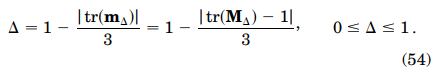

In [ ]:
s[0] = -1
test = s[:, None, None] * Q
test[0], Q[0]
# Flipp des Vorzeichens -> sollte dann entsprechend auch bei der

(array([[-0.51396756, -0.56281525,  0.64736106],
        [-0.57473897, -0.33429206, -0.74694306],
        [-0.6367986 ,  0.75596813,  0.15165658]]),
 array([[ 0.51396756,  0.56281525, -0.64736106],
        [ 0.57473897,  0.33429206,  0.74694306],
        [ 0.6367986 , -0.75596813, -0.15165658]]))

In [35]:
U.shape, S.shape, Vt.shape, Q.shape, s.shape

((65536, 3, 3), (65536, 3), (65536, 3, 3), (65536, 3, 3), (65536,))

In [51]:
vn.shape

(65536,)

In [ ]:
# ---- 4) Retardance-Vektor aus mR --------------------------------------
v = np.stack([mR[:, 1, 2] - mR[:, 2, 1],
				mR[:, 2, 0] - mR[:, 0, 2],
				mR[:, 0, 1] - mR[:, 1, 0]], axis=1)          # v ist der Antisymmetrische Anteil von mR
vn = np.linalg.norm(v, axis=1)
cosR = (np.trace(mR, axis1=1, axis2=2) - 1) / 2
R = np.arctan2(vn / 2, cosR)                 # stabiler als arccos

In [ ]:


# Achse: normal aus v, nahe R = π aus dem symmetrischen Anteil
n = v / np.maximum(vn, eps)[:, None]

near_pi = (vn < 1e-3) & (cosR < 0)
if near_pi.any():
	idx = np.nonzero(near_pi)[0]
	Ssym = 0.5 * (mR[idx] + mR[idx].transpose(0, 2, 1))
	B = (Ssym - cosR[idx, None, None] * I3) / (1 - cosR[idx])[:, None, None]
	k = np.argmax(np.einsum('nii->ni', B), axis=1)
	col = B[np.arange(len(idx)), :, k]
	col /= np.maximum(np.linalg.norm(col, axis=1), eps)[:, None]
	sg = np.sign(np.einsum('ni,ni->n', col, v[idx]))
	sg[sg == 0] = 1.0
	n[idx] = col * sg[:, None]

a = R[:, None] * n                           # Retardance-Vektor
lin_ret = np.hypot(a[:, 0], a[:, 1])
circ_ret = a[:, 2]
orientation = 0.5 * np.arctan2(a[:, 1], a[:, 0])

return D, depol, lin_ret, circ_ret, orientation


In [52]:
def lin_ret_orientation_fast(M, eps=1e-12):
    m = M[:, 1:, 1:] / M[:, :1, :1]
    v1 = m[:, 1, 2] - m[:, 2, 1]
    v2 = m[:, 2, 0] - m[:, 0, 2]
    v3 = m[:, 0, 1] - m[:, 1, 0]
    tr = m[:, 0, 0] + m[:, 1, 1] + m[:, 2, 2]

    vn = np.sqrt(v1*v1 + v2*v2 + v3*v3)
    rho = np.hypot(tr, vn)
    R = np.arctan2(vn, tr) + np.arcsin(np.clip(vn / (2*np.maximum(rho, eps)), -1, 1))
    R = np.minimum(R, np.pi)

    lin = R * np.hypot(v1, v2) / np.maximum(vn, eps)
    theta = 0.5 * np.arctan2(v2, v1)
    return lin, theta

Time for lu_chipman_svd: 0.4646 seconds
Time for lu_chipman_svd: 0.0063 seconds



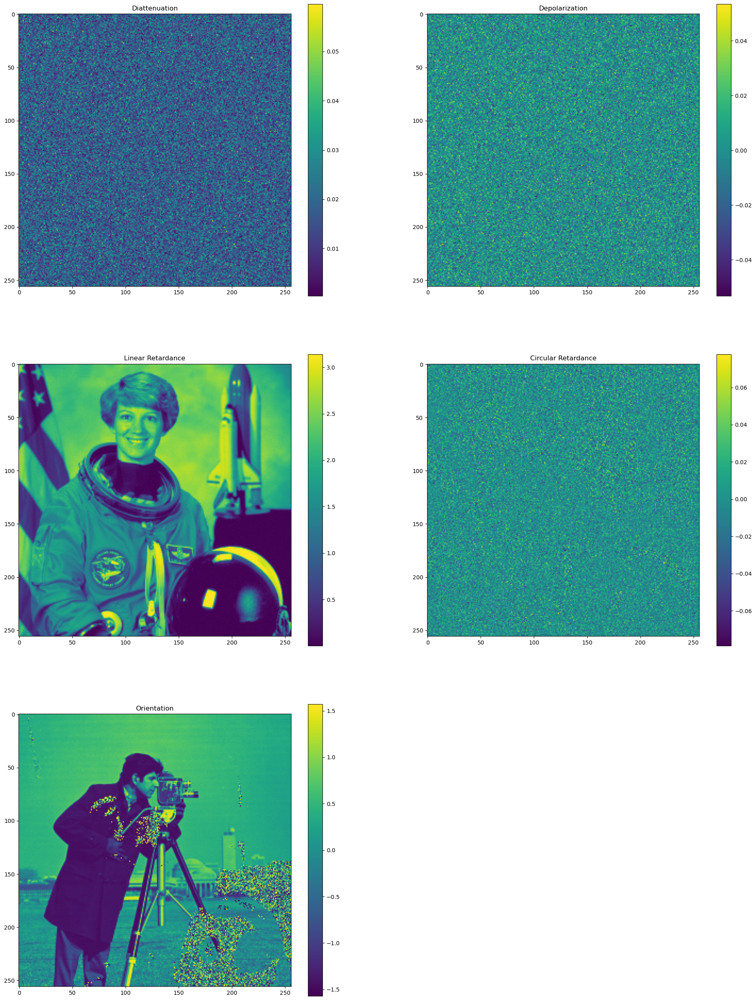

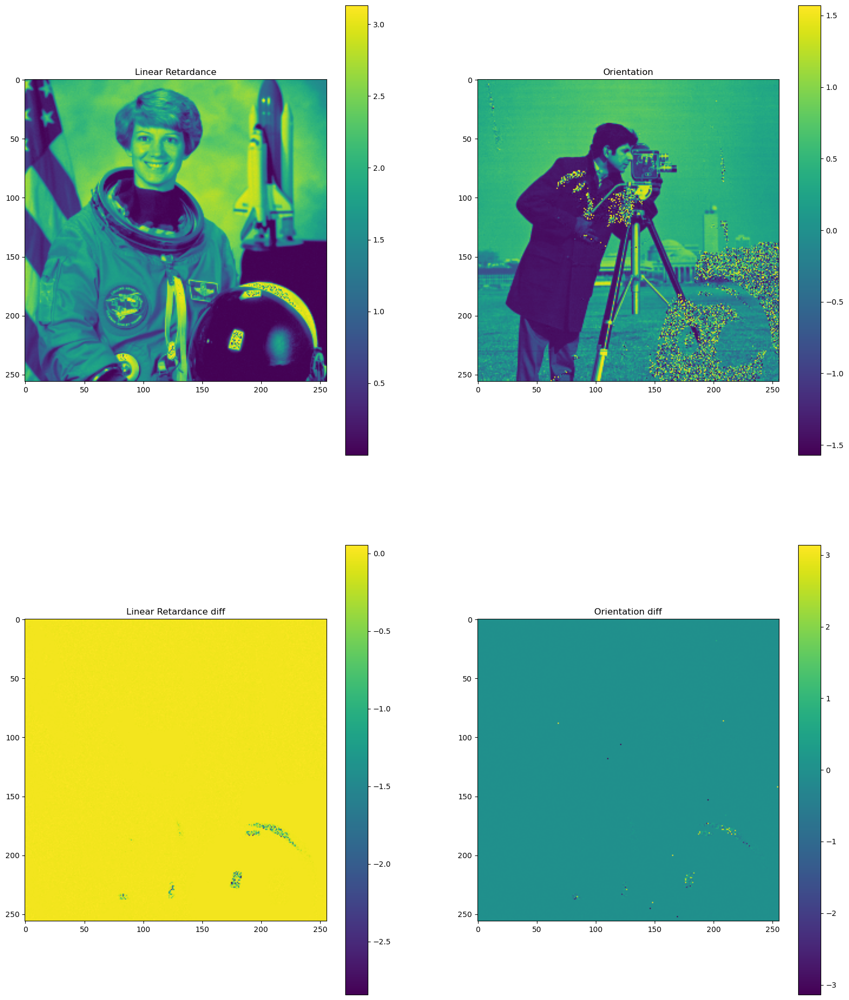

In [54]:
import time
strart = time.process_time()
MMD_D, MMD_Delta, MMD_LR, MMD_CR, MMD_psi = lu_chipman_svd(Reconst)
end = time.process_time()
print(f"Time for lu_chipman_svd: {end - strart:.4f} seconds")

strart = time.process_time()
ret, ori = lin_ret_orientation_fast(Reconst)
end = time.process_time()
print(f"Time for lu_chipman_svd: {end - strart:.4f} seconds")

print()
plt.figure(figsize=(24, 32))
plt.subplot(3, 2, 1)
plt.title("Diattenuation")
plt.imshow(MMD_D.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3, 2, 2)
plt.title("Depolarization")
plt.imshow(MMD_Delta.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,3)
plt.title("Linear Retardance")
plt.imshow(MMD_LR.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,4)
plt.title("Circular Retardance")
plt.imshow(MMD_CR.reshape(256,256), cmap="viridis")
plt.colorbar()

plt.subplot(3,2,5)
plt.title("Orientation")
plt.imshow(MMD_psi.reshape(256,256), cmap="viridis")
plt.colorbar()
plt.show()

plt.figure(figsize=(20, 24))
plt.subplot(2,2,1)
plt.title("Linear Retardance")
plt.imshow(ret.reshape(256,256), cmap="viridis")
plt.colorbar()
plt.subplot(2,2,2)
plt.title("Orientation")
plt.imshow(ori.reshape(256,256), cmap="viridis")
plt.colorbar()
plt.subplot(2,2,3)
plt.title("Linear Retardance diff")
plt.imshow(ret.reshape(256,256)-MMD_LR.reshape(256,256), cmap="viridis")
plt.colorbar()
plt.subplot(2,2,4)
plt.title("Orientation diff")
plt.imshow(ori.reshape(256,256)-MMD_psi.reshape(256,256), cmap="viridis")
plt.colorbar()